# What is Data Visualization
- Data Visualization is the process of representing data using charts, graphs and plots to understand patterns and insights easily.

# Why do we use it
- To understand data easily.
- To identify trends and patterns.
- To compare categories.
- To identify outliers.
- To communicate business insights.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/Users/nidagallusandeep/Downloads/day42_data_visualization.csv")
df.head()

,Order_ID,Date,City,Category,Payment_Method,Order_Status,Quantity,Unit_Price_INR,Discount_Percent,Revenue_INR
0,ORD001,2026-01-01,Chennai,Electronics,UPI,Delivered,4,9970,10,35892.0
1,ORD002,2026-01-02,Kurnool,Grocery,UPI,Delivered,5,11048,10,49716.0
2,ORD003,2026-01-03,Hyderabad,Clothing,Credit Card,Pending,3,1075,0,3225.0
3,ORD004,2026-01-04,Chennai,Clothing,Debit Card,Delivered,5,12506,10,56277.0
4,ORD005,2026-01-05,Bengaluru,Electronics,Debit Card,Delivered,5,8526,10,38367.0


In [4]:
df.shape

(60, 10)

In [6]:
df.columns

Index(['Order_ID', 'Date', 'City', 'Category', 'Payment_Method',
       'Order_Status', 'Quantity', 'Unit_Price_INR', 'Discount_Percent',
       'Revenue_INR'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          60 non-null     object 
 1   Date              60 non-null     object 
 2   City              60 non-null     object 
 3   Category          60 non-null     object 
 4   Payment_Method    60 non-null     object 
 5   Order_Status      60 non-null     object 
 6   Quantity          60 non-null     int64  
 7   Unit_Price_INR    60 non-null     int64  
 8   Discount_Percent  60 non-null     int64  
 9   Revenue_INR       60 non-null     float64
dtypes: float64(1), int64(3), object(6)
memory usage: 4.8+ KB


In [9]:
df.describe()

,Quantity,Unit_Price_INR,Discount_Percent,Revenue_INR
count,60.000000,60.000000,60.000000,60.000000
mean,3.583333,7698.333333,10.666667,24293.389167
std,1.565428,4229.299243,6.793982,16753.482536
min,1.000000,364.000000,0.000000,309.400000
25%,2.000000,4218.000000,5.000000,9140.587500
50%,4.000000,8180.500000,10.000000,21848.575000
75%,5.000000,11062.250000,15.000000,36510.750000
max,6.000000,14905.000000,20.000000,59408.000000


In [10]:
df.isnull().sum()

Order_ID            0
Date                0
City                0
Category            0
Payment_Method      0
Order_Status        0
Quantity            0
Unit_Price_INR      0
Discount_Percent    0
Revenue_INR         0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

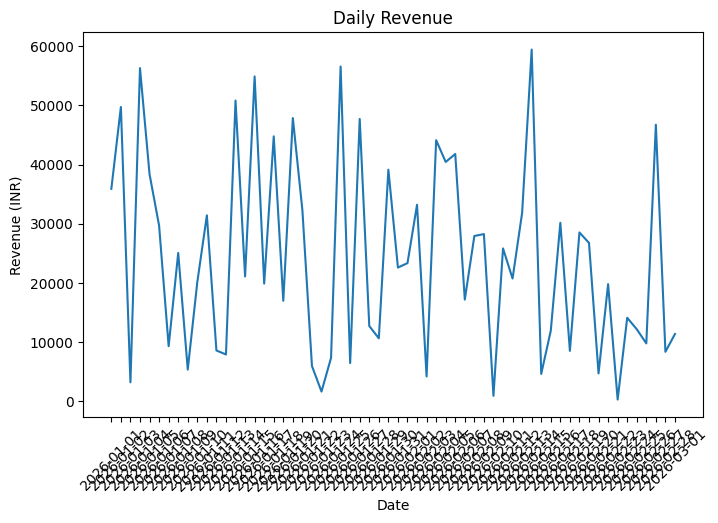

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(df["Date"], df["Revenue_INR"])
plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.show()

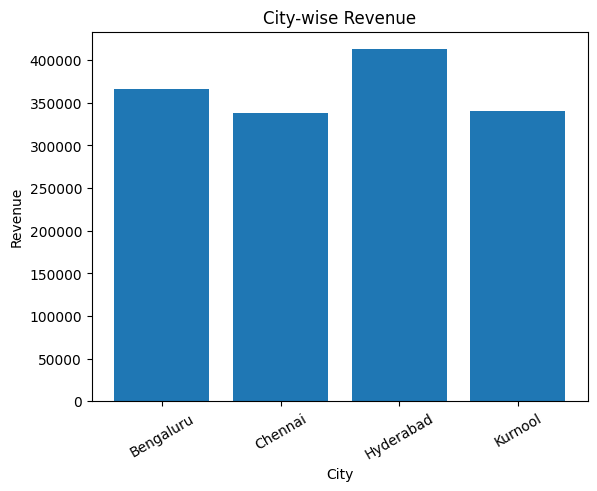

In [13]:
city_revenue = df.groupby("City")["Revenue_INR"].sum()
plt.bar(city_revenue.index, city_revenue.values)
plt.title("City-wise Revenue")
plt.xlabel("City")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.show()

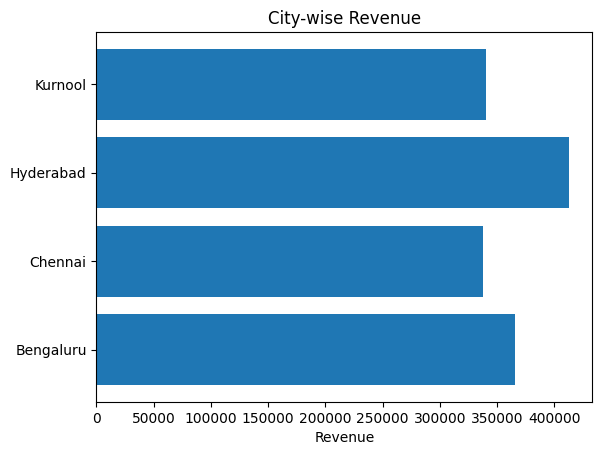

In [14]:
plt.barh(city_revenue.index, city_revenue.values)
plt.title("City-wise Revenue")
plt.xlabel("Revenue")
plt.show()

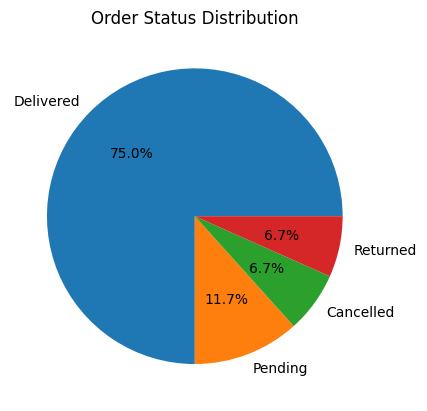

In [15]:
status_counts = df["Order_Status"].value_counts()
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%")
plt.title("Order Status Distribution")
plt.show()

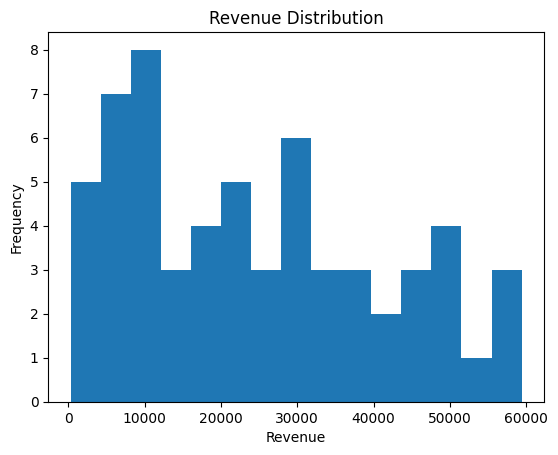

In [16]:
plt.hist(df["Revenue_INR"], bins=15)
plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

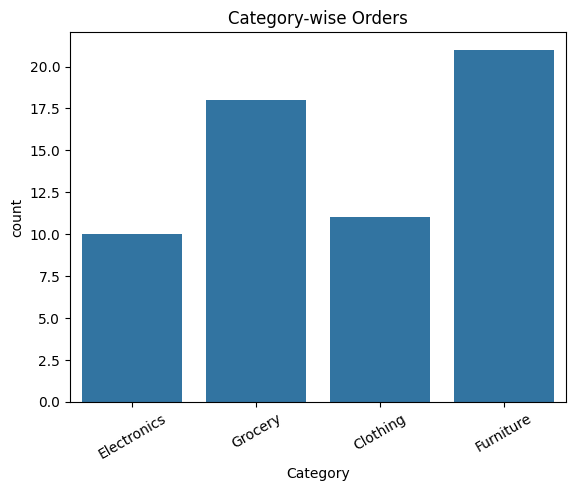

In [17]:
sns.countplot(data=df, x="Category")
plt.title("Category-wise Orders")
plt.xticks(rotation=30)
plt.show()

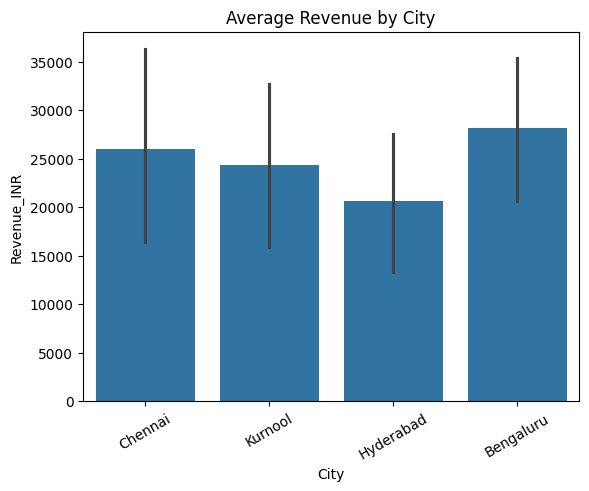

In [18]:
sns.barplot(data=df, x="City", y="Revenue_INR")
plt.title("Average Revenue by City")
plt.xticks(rotation=30)
plt.show()

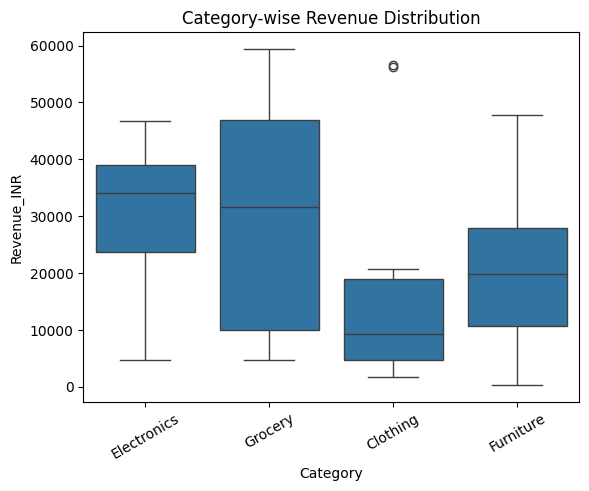

In [19]:
sns.boxplot(data=df, x="Category", y="Revenue_INR")
plt.title("Category-wise Revenue Distribution")
plt.xticks(rotation=30)
plt.show()

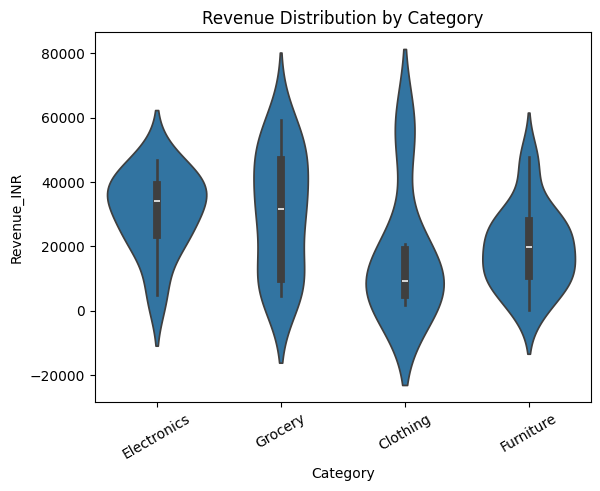

In [20]:
sns.violinplot(data=df, x="Category", y="Revenue_INR")
plt.title("Revenue Distribution by Category")
plt.xticks(rotation=30)
plt.show()

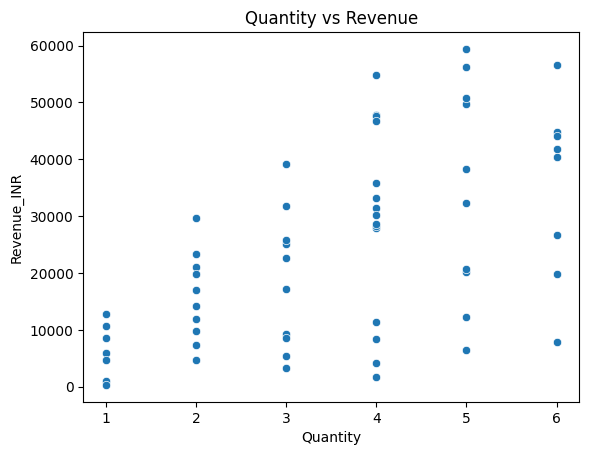

In [21]:
sns.scatterplot(
    data=df,
    x="Quantity",
    y="Revenue_INR")
plt.title("Quantity vs Revenue")
plt.show()

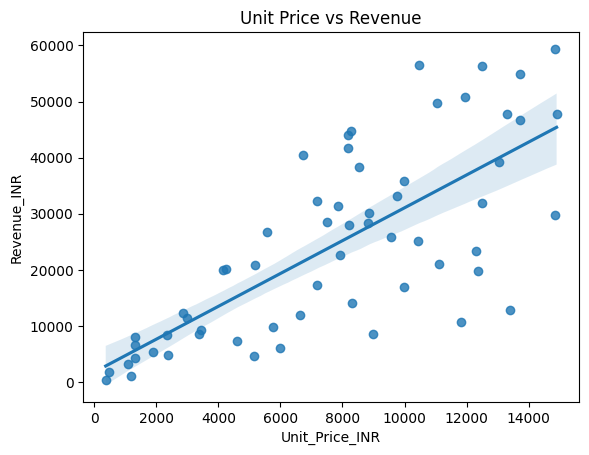

In [22]:
sns.regplot(
    data=df,
    x="Unit_Price_INR",
    y="Revenue_INR")
plt.title("Unit Price vs Revenue")
plt.show()

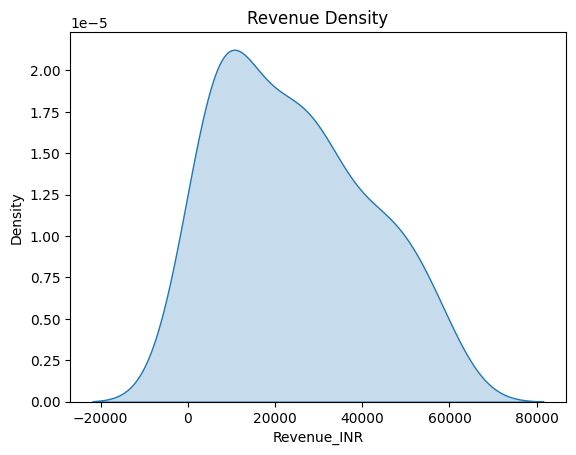

In [23]:
sns.kdeplot(data=df, x="Revenue_INR", fill=True)
plt.title("Revenue Density")
plt.show()

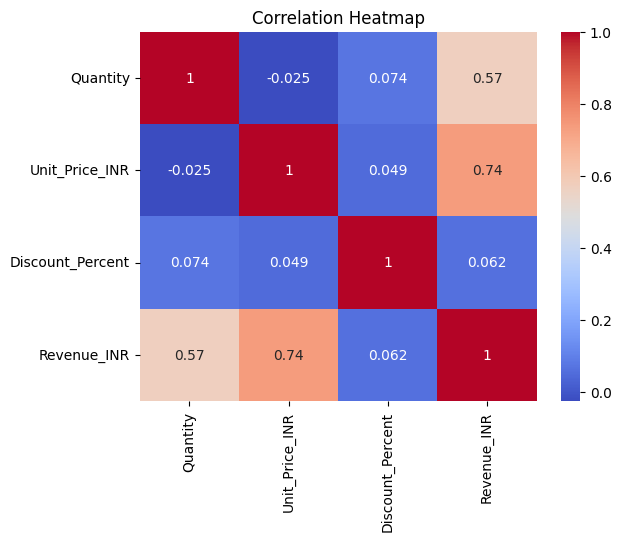

In [24]:
numeric_df = df.select_dtypes(include="number")
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

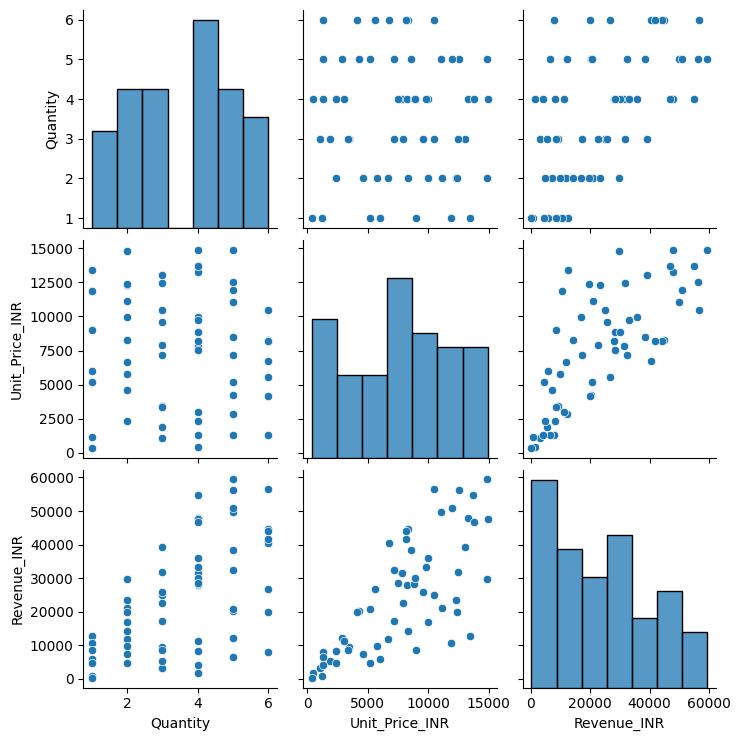

In [25]:
sns.pairplot(df[["Quantity", "Unit_Price_INR", "Revenue_INR"]])
plt.show()

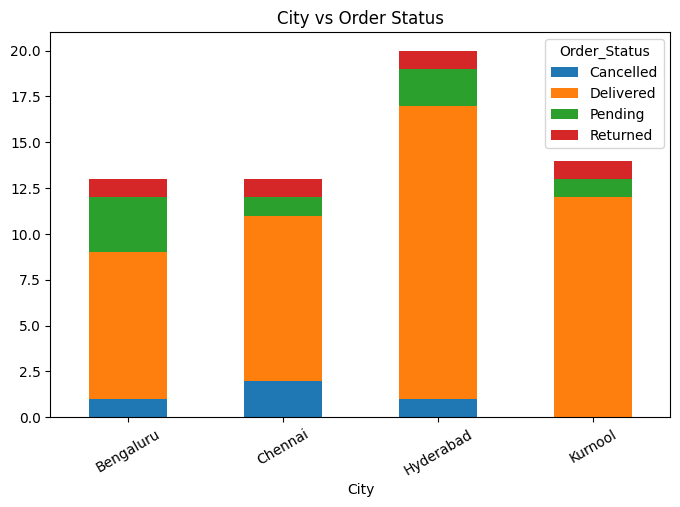

In [26]:
table = pd.crosstab(df["City"],df["Order_Status"])
table.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("City vs Order Status")
plt.xticks(rotation=30)
plt.show()

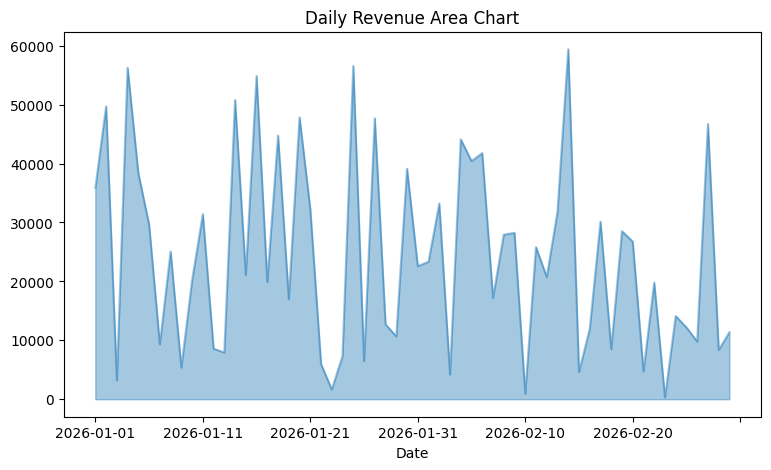

In [27]:
daily_revenue = df.groupby("Date")["Revenue_INR"].sum()
daily_revenue.plot(
    kind="area",
    figsize=(9, 5),
    alpha=0.4)
plt.title("Daily Revenue Area Chart")
plt.show()

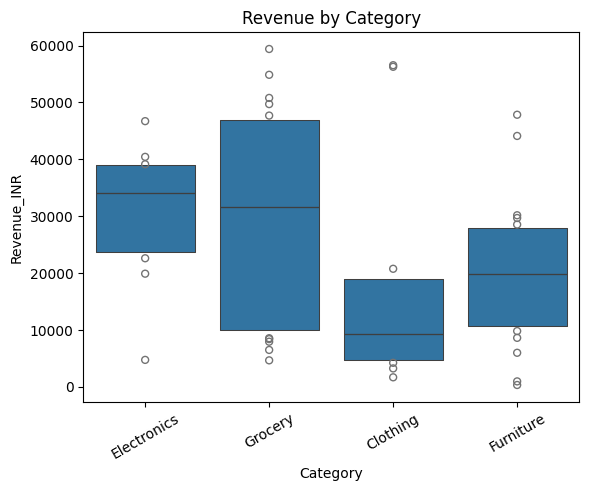

In [28]:
sns.boxenplot(
    data=df,
    x="Category",
    y="Revenue_INR")
plt.title("Revenue by Category")
plt.xticks(rotation=30)
plt.show()

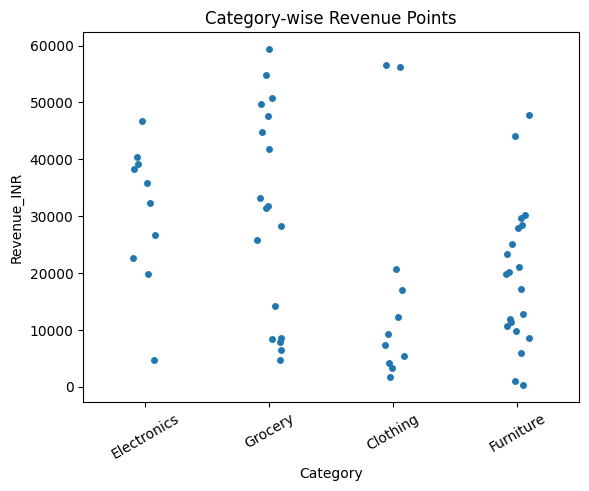

In [29]:
sns.stripplot(
    data=df,
    x="Category",
    y="Revenue_INR",
    jitter=True)
plt.title("Category-wise Revenue Points")
plt.xticks(rotation=30)
plt.show()

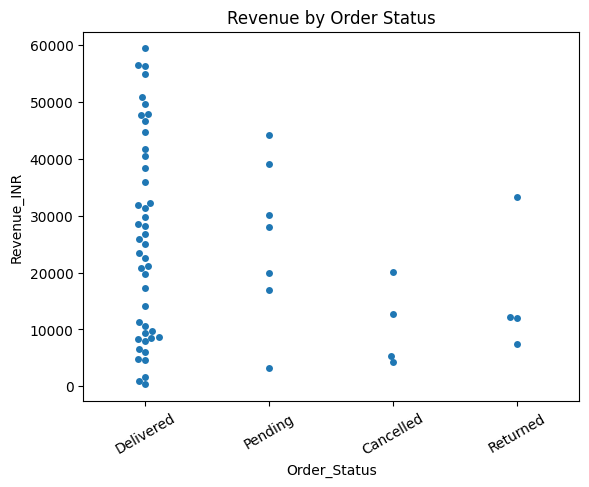

In [30]:
sns.swarmplot(
    data=df,
    x="Order_Status",
    y="Revenue_INR")
plt.title("Revenue by Order Status")
plt.xticks(rotation=30)
plt.show()

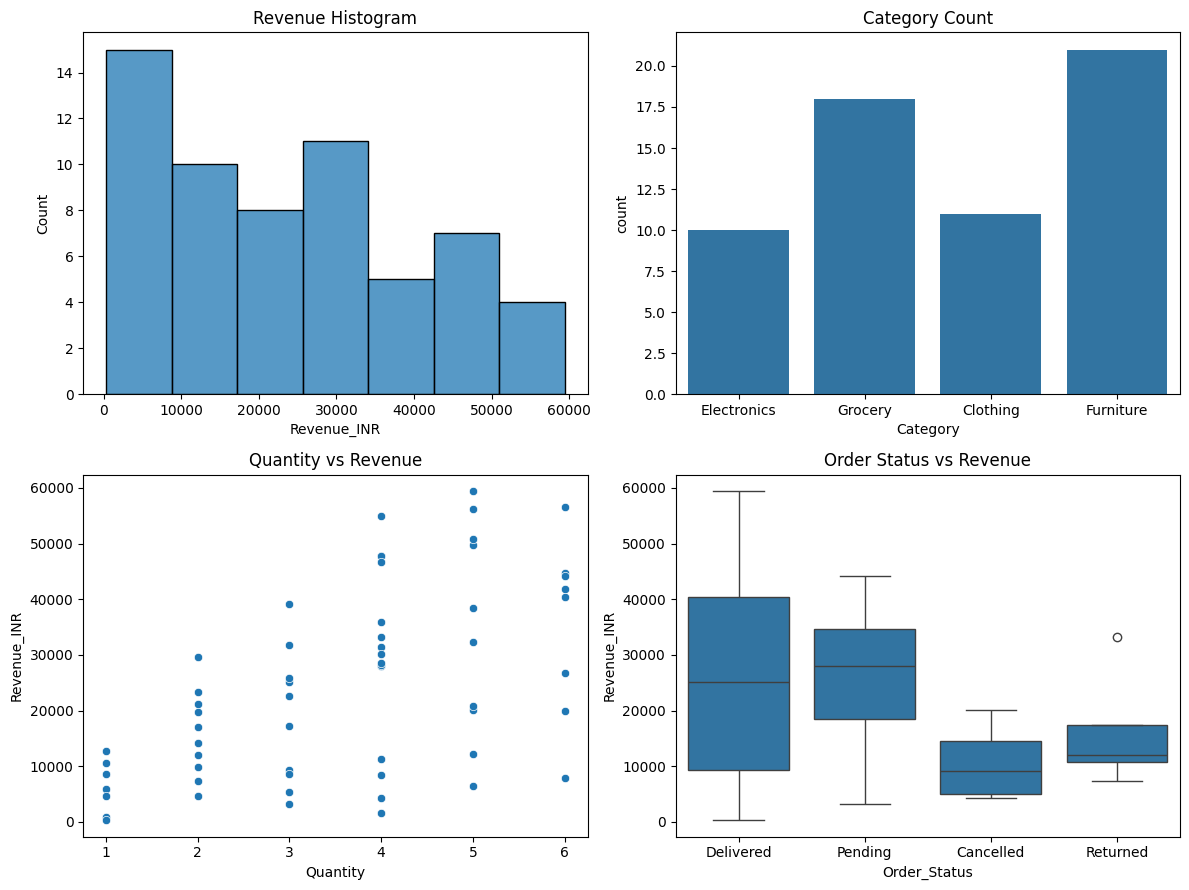

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(data=df, x="Revenue_INR", ax=axes[0, 0])
axes[0, 0].set_title("Revenue Histogram")
sns.countplot(data=df, x="Category", ax=axes[0, 1])
axes[0, 1].set_title("Category Count")
sns.scatterplot(
    data=df,
    x="Quantity",
    y="Revenue_INR",
    ax=axes[1, 0])
axes[1, 0].set_title("Quantity vs Revenue")
sns.boxplot(
    data=df,
    x="Order_Status",
    y="Revenue_INR",
    ax=axes[1, 1])
axes[1, 1].set_title("Order Status vs Revenue")
plt.tight_layout()
plt.show()